# 自動遊玩 8×8 寶石方塊（OpenCV + PyAutoGUI）

這個 notebook 會：

1. **畫面擷取與辨識**：用 PyAutoGUI 截圖，OpenCV 自動偵測 8×8 盤面，依 HSV/Lab 顏色將每格寶石分類。
2. **決策邏輯**：模擬所有相鄰交換，用啟發式評分排序（3 連 +100、4 連 +500、5 連 +1000，底部列額外加權）。
3. **行動執行**：用 PyAutoGUI 點擊或拖曳，執行目前最高分的交換。
4. **防卡死**：沒有可消除交換時，隨機交換／點擊，或按下指定的「重整」按鈕。
5. **安全保護**：PyAutoGUI Fail-Safe 已開啟；把滑鼠移到螢幕左上角，或按 Ctrl+C，即可中止。

## 使用前準備

```text
C:\Users\user\anaconda3\Scripts\conda.exe run -n iem_python python -m pip install opencv-python
```

* Notebook kernel 請選 **iem_python**。
* 玩遊戲的瀏覽器與本 notebook 要放在同一個桌面；擷取的是整個螢幕。
* 校準與遊玩期間**不要縮放/捲動網頁**，盤面必須完整可見。
* 第一次執行請照順序跑：**第 7 格（偵測格線）→ 第 8 格（顏色校準）→ 第 9 格（唯讀分析）→ 第 10 格（實際遊玩）**。

## 若自動偵測格線失敗

在第 1 格把 `MANUAL_BOX` 設成 `(left, top, width, height)`，單位的螢幕像素。第 7 格失敗時會顯示一張畫有像素座標的截圖，可直接讀出左上角與寬高。

## 安全提醒

* 預設 `AUTO_PLAY = False`，只會分析、不會動滑鼠。
* 確認第 7～9 格的格線與盤面判讀都正確後，才把第 10 格改成 `True`。
* 遊戲網頁若在背景或視窗被遮住，截圖會抓到別的畫面；請保持遊戲視窗在最上層。

In [356]:
# ============================================================
# 1. 匯入套件與全域設定
# ============================================================
import random
import time
from dataclasses import dataclass, field
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pyautogui as pyg

try:
    from IPython.display import Image as IPImage
    from IPython.display import display
except Exception:  # 在純 Python 環境執行時仍可使用分析功能
    IPImage = None
    display = None


# ---------- 安全機制 ----------
# Fail-Safe：滑鼠移到螢幕左上角時，PyAutoGUI 會拋出 FailSafeException。
pyg.FAILSAFE = True
pyg.PAUSE = 0.05  # 每次滑鼠動作後暫停 0.05 秒，避免動作太快


# ---------- 盤面設定 ----------
ROWS = 8
COLS = 8
GEM_TYPES = 6  # 寶石種類數；Bejeweled 類遊戲常見 6～7 種，請依遊戲調整

# 自動偵測失敗時，手動指定盤面外框：(left, top, width, height)
# 例如 MANUAL_BOX = (320, 360, 320, 320)
MANUAL_BOX = None

# 每格取樣中央多大比例；0.46 代表只取格子中央 46% 的區域，避開邊框與反光
SAMPLE_RATIO = 0.46

# 顏色分群參數（Lab 色彩空間，數值越小越嚴格）
PALETTE_K = GEM_TYPES
PALETTE_MERGE_DIST = 22.0  # 兩個叢集中心太近就合併（避免同一種顏色被拆成兩類）
PALETTE_MAX_DIST = 48.0    # 新顏色離所有叢集都超過此距離時，視為未知（-1）


# ---------- 啟發式評分 ----------
MATCH_SCORES = {3: 100, 4: 500, 5: 1000}  # 5 連以上一律 1000
BOTTOM_ROW_BONUS = 12.0  # 每顆被消除的寶石，依列數加權：列 0 加 0、列 7 加 84


# ---------- 滑鼠與動畫 ----------
SWAP_MODE = "drag"     # "drag"：按住拖曳；"click"：點第一顆再點第二顆
SWAP_DURATION = 0.18   # 滑鼠移動動畫秒數
HOVER_PAUSE = 0.10     # 移到目標後、按下前的停頓
CLICK_PAUSE = 0.10     # 兩次點擊之間的停頓
SETTLE_TIME = 0.60     # 交換後先等動畫開始
STABLE_INTERVAL = 0.22 # 連續讀取盤面的間隔
STABLE_TIMEOUT = 4.0   # 等盤面穩定的最長時間
STABLE_FRAMES = 2      # 連續幾次盤面相同才視為穩定


# ---------- 防卡死 ----------
STUCK_ACTION = "random"  # "random"：隨機交換；"shuffle"：點擊 SHUFFLE_POINT
SHUFFLE_POINT = None     # 重整按鈕的螢幕座標，例如 (980, 700)
STUCK_RANDOM_TRIES = 3   # 每次卡死最多隨機嘗試幾次
MAX_STUCK_ROUNDS = 4     # 連續幾輪防卡死都失敗就停止


# ---------- 輸出 ----------
DEBUG_DIR = Path("shots")
PREVIEW_WIDTH = 900


print("OpenCV:", cv2.__version__)
print("NumPy :", np.__version__)
print("PyAutoGUI Fail-Safe 已開啟：把滑鼠移到左上角即可中止。")

# 若 kernel 在安裝 Pillow 前就啟動，pyautogui 會無法截圖
if getattr(pyg.screenshot, "__name__", "") == "_couldNotImportPyScreeze":
    print("\n警告：這個 kernel 的 pyautogui 無法截圖（缺少 Pillow 或 kernel 太舊）。")
    print("請安裝 Pillow，執行 Restart Kernel，再從第 1 格重新執行。")

OpenCV: 5.0.0
NumPy : 2.5.4
PyAutoGUI Fail-Safe 已開啟：把滑鼠移到左上角即可中止。


In [357]:
# ============================================================
# 2. 影像工具、螢幕擷取與 8×8 網格偵測
# ============================================================
# 這裡的影像格式一律是 OpenCV 的 BGR（不是 RGB）。
# 顏色辨識另外轉成 HSV（找彩色區域）與 Lab（計算顏色距離）。


@dataclass
class GridSpec:
    """8×8 盤面的幾何資訊，單位都是螢幕像素。"""

    left: float
    top: float
    cell_w: float
    cell_h: float
    rows: int = ROWS
    cols: int = COLS

    @property
    def width(self):
        return self.cell_w * self.cols

    @property
    def height(self):
        return self.cell_h * self.rows

    def center(self, row, col):
        """回傳第 row 列、第 col 欄寶石中心的整數座標。"""
        x = self.left + (col + 0.5) * self.cell_w
        y = self.top + (row + 0.5) * self.cell_h
        return int(round(x)), int(round(y))

    def cell_rect(self, row, col):
        """回傳格子的左上、右下座標 (x0, y0, x1, y1)。"""
        x0 = int(round(self.left + col * self.cell_w))
        y0 = int(round(self.top + row * self.cell_h))
        x1 = int(round(self.left + (col + 1) * self.cell_w))
        y1 = int(round(self.top + (row + 1) * self.cell_h))
        return x0, y0, x1, y1


def grab_screen():
    """用 PyAutoGUI 擷取整個螢幕，轉成 OpenCV 的 BGR ndarray。"""
    pil_image = pyg.screenshot().convert("RGB")
    return cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)


def show_image(image, title=None, max_width=PREVIEW_WIDTH):
    """在 notebook 顯示 BGR 影像；沒有 IPython 時只印出尺寸。"""
    if image is None:
        print("[沒有影像]")
        return
    shown = image.copy()
    h, w = shown.shape[:2]
    if w > max_width:
        scale = max_width / w
        shown = cv2.resize(shown, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    if display is None or IPImage is None:
        print(f"[影像] {title or ''} 原始尺寸 {w}x{h}")
        return
    ok, buffer = cv2.imencode(".png", shown)
    if not ok:
        print("[影像編碼失敗]")
        return
    display(IPImage(data=buffer.tobytes()))
    if title:
        print(title)


def save_image(image, label="capture"):
    """把影像存到 shots/，回傳路徑。"""
    DEBUG_DIR.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")[:-3]
    path = DEBUG_DIR / f"{label}_{stamp}.png"
    cv2.imwrite(str(path), image)
    return path


def sample_cell_bgr(image, grid, row, col, ratio=SAMPLE_RATIO):
    """取格子中央區域的中位數顏色（BGR）。

    使用中位數而不是平均數，可以避開寶石高光、邊框與反鋸齒造成的極端值。
    """
    x0, y0, x1, y1 = grid.cell_rect(row, col)
    h, w = image.shape[:2]
    x0, x1 = max(0, x0), min(w, x1)
    y0, y1 = max(0, y0), min(h, y1)
    if x1 <= x0 or y1 <= y0:
        return None

    pad_x = int(round((x1 - x0) * (1.0 - ratio) / 2.0))
    pad_y = int(round((y1 - y0) * (1.0 - ratio) / 2.0))
    patch = image[y0 + pad_y:y1 - pad_y, x0 + pad_x:x1 - pad_x]
    if patch.size == 0:
        return None
    return np.median(patch.reshape(-1, 3), axis=0).astype(np.float32)


def _odd(value):
    value = int(max(1, value))
    return value if value % 2 == 1 else value + 1


def _near_square_boxes(mask, min_area):
    """從二值遮罩找出接近正方形的候選外框。"""
    kernel_size = _odd(max(5, min(mask.shape[:2]) // 120))
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((kernel_size, kernel_size), np.uint8))
    opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    contours, _ = cv2.findContours(opened, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boxes = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        area = w * h
        if area < min_area or w < 80 or h < 80:
            continue
        aspect = w / max(h, 1)
        if not (0.70 <= aspect <= 1.43):  # 8×8 盤面應該接近正方形
            continue
        score = area * min(aspect, 1.0 / aspect)
        boxes.append((x, y, w, h, score))
    return boxes


def _cluster_positions(values, k):
    """把一維座標分成 k 群（例如 64 顆寶石的 x 座標 → 8 條欄線）。"""
    values = np.asarray(values, dtype=np.float32).reshape(-1, 1)
    if len(values) < k:
        return None

    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 80, 0.1)
    _, labels, centers = cv2.kmeans(values, k, None, criteria, 10, cv2.KMEANS_PP_CENTERS)
    centers = np.sort(centers.ravel())
    counts = np.bincount(labels.ravel(), minlength=k)
    if len(counts) < k or counts.min() < 2:
        return None

    diffs = np.diff(centers)
    if len(diffs) == 0 or diffs.mean() < 3:
        return None
    # 每一欄/列的間距應該差不多；差太多代表偵測到的不是整齊的盤面
    if diffs.std() > max(8.0, diffs.mean() * 0.35):
        return None
    if centers[-1] - centers[0] < (k - 1) * 6:
        return None
    return centers


def _grid_from_gem_centers(image, region=None):
    """用 HSV 找出彩色寶石輪廓，再由寶石中心反推 8×8 網格。

    region=(x, y, w, h) 時只分析這個區域，可避免網頁其他彩色元件干擾。
    """
    if region is None:
        x0, y0 = 0, 0
        w0, h0 = image.shape[1], image.shape[0]
    else:
        x0, y0, w0, h0 = [int(v) for v in region]
        x0 = max(0, x0)
        y0 = max(0, y0)
        w0 = min(w0, image.shape[1] - x0)
        h0 = min(h0, image.shape[0] - y0)
    if w0 < 80 or h0 < 80:
        return None

    roi = image[y0:y0 + h0, x0:x0 + w0]
    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
    saturation, value = hsv[:, :, 1], hsv[:, :, 2]

    # 自適應飽和度門檻：盤面底板本身可能也是有色的（例如深棕色），
    # 若用固定門檻，底板會和寶石黏成一大塊。以整張 ROI 的中位飽和度
    # 往上加一段，只留下比底板更鮮豔的寶石。
    saturation_median = float(np.median(saturation))
    saturation_threshold = max(60.0, min(170.0, saturation_median + 30.0))
    mask = np.where((saturation >= saturation_threshold) & (value >= 45), 255, 0).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    area = w0 * h0
    centers = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        box_area = w * h
        if box_area < area * 0.00005 or box_area > area * 0.02:
            continue
        if w < 8 or h < 8:
            continue
        aspect = w / max(h, 1)
        if not (0.45 <= aspect <= 2.2):
            continue
        # 寶石通常填滿外接矩形；太稀疏的輪廓（文字、線條）先排除
        if cv2.contourArea(contour) / max(box_area, 1) < 0.30:
            continue
        centers.append((x + w / 2.0, y + h / 2.0))

    if len(centers) < 24:
        return None

    cols = _cluster_positions([p[0] for p in centers], COLS)
    rows = _cluster_positions([p[1] for p in centers], ROWS)
    if cols is None or rows is None:
        return None

    cell_w = float(np.median(np.diff(cols)))
    cell_h = float(np.median(np.diff(rows)))
    if cell_w < 6 or cell_h < 6:
        return None
    if not (0.50 <= cell_w / cell_h <= 2.0):
        return None

    grid = GridSpec(
        left=x0 + cols[0] - cell_w / 2.0,
        top=y0 + rows[0] - cell_h / 2.0,
        cell_w=cell_w,
        cell_h=cell_h,
    )

    # 驗證：大部分寶石中心都應該落在推測出來的格點附近
    matched = 0
    for cx, cy in centers:
        abs_x, abs_y = x0 + cx, y0 + cy
        col = int(round((abs_x - grid.left - cell_w / 2.0) / cell_w))
        row = int(round((abs_y - grid.top - cell_h / 2.0) / cell_h))
        if 0 <= row < ROWS and 0 <= col < COLS:
            gx, gy = grid.center(row, col)
            if abs(gx - abs_x) <= cell_w * 0.35 and abs(gy - abs_y) <= cell_h * 0.35:
                matched += 1
    if matched < max(24, int(len(centers) * 0.70)):
        return None
    return grid


def detect_grid(screen, manual_box=None, verbose=True):
    """自動偵測 8×8 盤面，回傳 GridSpec；失敗回傳 None。

    策略：
      1. 先用 HSV 彩色遮罩 / Canny 邊緣找出接近正方形的盤面外框。
      2. 在候選框內用寶石輪廓反推 8 條欄線與 8 條列線。
      3. 都找不到時，退回「全螢幕寶石中心」偵測。
      4. 最後才用外框平均切分。
    """
    if manual_box is not None:
        left, top, width, height = manual_box
        if width <= 0 or height <= 0:
            raise ValueError("MANUAL_BOX 的寬高必須大於 0")
        return GridSpec(float(left), float(top), width / COLS, height / ROWS)

    screen_h, screen_w = screen.shape[:2]
    screen_area = screen_h * screen_w
    hsv = cv2.cvtColor(screen, cv2.COLOR_BGR2HSV)
    saturation, value = hsv[:, :, 1], hsv[:, :, 2]

    color_mask = np.where((saturation >= 55) & (value >= 40), 255, 0).astype(np.uint8)
    gray = cv2.cvtColor(screen, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 40, 120)
    edges = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=1)

    candidates = []
    for mask in (color_mask, edges):
        candidates.extend(_near_square_boxes(mask, screen_area * 0.01))

    # 去除幾乎重複的候選框
    candidates.sort(key=lambda item: item[4], reverse=True)
    unique = []
    for box in candidates:
        if all(
            abs(box[0] - other[0]) > 20
            or abs(box[1] - other[1]) > 20
            or abs(box[2] - other[2]) > 20
            or abs(box[3] - other[3]) > 20
            for other in unique
        ):
            unique.append(box)

    if verbose and unique:
        print("自動偵測候選框：", [(x, y, w, h) for x, y, w, h, _ in unique[:5]])

    fallback = None
    for x, y, w, h, _ in unique[:8]:
        grid = _grid_from_gem_centers(screen, region=(x, y, w, h))
        if grid is not None:
            return grid
        if verbose:
            print(f"  候選框 ({x}, {y}, {w}, {h}) 找不到完整 8×8 寶石中心，先保留外框均分結果。")
        if fallback is None:
            fallback = GridSpec(float(x), float(y), w / COLS, h / ROWS)

    grid = _grid_from_gem_centers(screen)
    if grid is not None:
        return grid
    if fallback is not None:
        return fallback

    if verbose:
        print("自動偵測失敗：找不到足夠的寶石輪廓。")
    return None


def annotate_grid(screen, grid, board=None, palette=None):
    """在截圖上畫出格線、格點與判讀結果，用來確認座標是否正確。"""
    image = screen.copy()
    left, top = int(round(grid.left)), int(round(grid.top))
    right = int(round(grid.left + grid.width))
    bottom = int(round(grid.top + grid.height))

    for i in range(ROWS + 1):
        y = int(round(grid.top + i * grid.cell_h))
        cv2.line(image, (left, y), (right, y), (0, 255, 0), 1)
    for j in range(COLS + 1):
        x = int(round(grid.left + j * grid.cell_w))
        cv2.line(image, (x, top), (x, bottom), (0, 255, 0), 1)

    for r in range(ROWS):
        for c in range(COLS):
            x, y = grid.center(r, c)
            cv2.circle(image, (x, y), 2, (0, 255, 255), -1)
            if r == 0 or c == 0:
                cv2.putText(image, f"{r},{c}", (x - 10, y + 14),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 255, 255), 1, cv2.LINE_AA)
            if board is not None and palette is not None:
                index = board[r][c]
                if 0 <= index < len(palette.symbols):
                    text = palette.symbols[index]
                    cv2.putText(image, text, (x - 6, y - 6),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)
                    cv2.putText(image, text, (x - 6, y - 6),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)
    return image


def annotate_coordinates(screen, step=100):
    """畫出像素座標參考線，方便手動設定 MANUAL_BOX。"""
    image = screen.copy()
    h, w = image.shape[:2]
    for x in range(0, w, step):
        cv2.line(image, (x, 0), (x, h), (128, 128, 128), 1)
        cv2.putText(image, str(x), (x + 3, 16), cv2.FONT_HERSHEY_SIMPLEX,
                    0.45, (0, 255, 255), 1, cv2.LINE_AA)
    for y in range(0, h, step):
        cv2.line(image, (0, y), (w, y), (128, 128, 128), 1)
        cv2.putText(image, str(y), (3, y + 16), cv2.FONT_HERSHEY_SIMPLEX,
                    0.45, (0, 255, 255), 1, cv2.LINE_AA)
    return image

In [358]:
# ============================================================
# 3. 寶石顏色辨識（HSV 找寶石、Lab 分群）
# ============================================================
# 作法是「先學這個盤面的調色盤」：
#   1. 取 64 格中央的中位數顏色。
#   2. 轉成 CIELAB，用 k-means 分成 GEM_TYPES 群。
#   3. 太接近的群中心合併，避免同一種寶石被拆成兩類。
#   4. 之後每一格都用「最近的群中心」判定種類。
# 這樣不需要事先硬編碼每款遊戲的顏色，換遊戲只要重跑校準。


@dataclass
class GemPalette:
    """盤面學到的寶石調色盤。"""

    centers_lab: np.ndarray
    symbols: list
    names: list
    colors_bgr: list
    max_dist: float = PALETTE_MAX_DIST

    def classify(self, lab_color):
        """回傳最近的寶石種類索引；太遠則回傳 -1（未知）。"""
        if lab_color is None:
            return -1
        distances = np.linalg.norm(self.centers_lab - np.asarray(lab_color, dtype=np.float32), axis=1)
        index = int(np.argmin(distances))
        if distances[index] > self.max_dist:
            return -1
        return index


def bgr_to_lab(bgr):
    """單一 BGR 顏色 → Lab（float32 向量）。"""
    array = np.asarray(bgr, dtype=np.uint8).reshape(1, 1, 3)
    return cv2.cvtColor(array, cv2.COLOR_BGR2LAB).reshape(3).astype(np.float32)


def lab_to_bgr(lab):
    """單一 Lab 顏色 → BGR。"""
    array = np.asarray(lab, dtype=np.float32).reshape(1, 1, 3)
    return cv2.cvtColor(np.clip(array, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR).reshape(3)


def color_name(bgr):
    """把顏色轉成容易讀的中文名稱（HSV 色相 + 飽和度/亮度）。"""
    b, g, r = [int(v) for v in bgr]
    hsv = cv2.cvtColor(np.uint8([[[b, g, r]]]), cv2.COLOR_BGR2HSV)[0, 0]
    h, s, v = [int(x) for x in hsv]

    if v < 35:
        return "黑"
    if s < 45:
        return "白/灰"
    if h < 8 or h >= 172:
        return "紅"
    if h < 22:
        return "橙"
    if h < 34:
        return "黃"
    if h < 78:
        return "綠"
    if h < 100:
        return "青"
    if h < 130:
        return "藍"
    if h < 155:
        return "紫"
    return "粉紅"


def _merge_centers(centers, counts, threshold):
    """把距離小於 threshold 的群中心合併（加權平均）。"""
    centers = [np.asarray(c, dtype=np.float32) for c in centers]
    counts = [float(c) for c in counts]

    while len(centers) > 1:
        best_i = best_j = -1
        best_distance = float("inf")
        for i in range(len(centers)):
            for j in range(i + 1, len(centers)):
                distance = float(np.linalg.norm(centers[i] - centers[j]))
                if distance < best_distance:
                    best_i, best_j, best_distance = i, j, distance
        if best_distance > threshold:
            break

        total = counts[best_i] + counts[best_j]
        centers[best_i] = (centers[best_i] * counts[best_i] + centers[best_j] * counts[best_j]) / total
        counts[best_i] = total
        del centers[best_j]
        del counts[best_j]

    return centers, counts


def learn_palette(screen, grid, k=PALETTE_K, verbose=True):
    """從目前盤面學習寶石調色盤。請在盤面靜止、沒有動畫時執行。"""
    samples = []
    for r in range(ROWS):
        for c in range(COLS):
            bgr = sample_cell_bgr(screen, grid, r, c)
            if bgr is not None:
                samples.append(bgr_to_lab(bgr))

    if len(samples) < ROWS * COLS * 0.5:
        raise RuntimeError("可取樣的格子太少，請確認 MANUAL_BOX 或格線偵測是否正確。")

    k = min(int(k), len(samples))
    data = np.asarray(samples, dtype=np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(data, k, None, criteria, 10, cv2.KMEANS_PP_CENTERS)

    counts = np.bincount(labels.ravel(), minlength=k).astype(float)
    centers, _ = _merge_centers(centers, counts, PALETTE_MERGE_DIST)

    # 依 HSV 色相排序，讓代號在同一個盤面上直覺且穩定
    ordered = []
    for center in centers:
        bgr = lab_to_bgr(center)
        hsv = cv2.cvtColor(np.uint8([[bgr]]), cv2.COLOR_BGR2HSV)[0, 0]
        h, s, v = [int(x) for x in hsv]
        ordered.append(((1 if s < 45 else 0), h, -s, -v, center, bgr))
    ordered.sort(key=lambda item: item[:4])

    centers_sorted = np.asarray([item[4] for item in ordered], dtype=np.float32)
    colors_bgr = [item[5] for item in ordered]
    symbols = [chr(ord("A") + i) for i in range(len(centers_sorted))]

    names = []
    used = {}
    for bgr in colors_bgr:
        base = color_name(bgr)
        used[base] = used.get(base, 0) + 1
        names.append(base if used[base] == 1 else f"{base}{used[base]}")

    palette = GemPalette(centers_sorted, symbols, names, colors_bgr)
    if verbose:
        if len(palette.symbols) < 3:
            print(f"警告：只學到 {len(palette.symbols)} 種顏色，可能不是遊戲盤面。")
        print(f"已學到 {len(palette.symbols)} 種寶石：" + palette_legend(palette))
    return palette


def palette_legend(palette):
    """回傳「A=紅  B=藍 ...」的顏色對照字串。"""
    return "  ".join(
        f"{symbol}={name}" for symbol, name in zip(palette.symbols, palette.names)
    )


def read_board(screen, grid, palette):
    """讀取 8×8 盤面，回傳二維整數陣列；-1 代表無法辨識。"""
    board = []
    for r in range(ROWS):
        row = []
        for c in range(COLS):
            bgr = sample_cell_bgr(screen, grid, r, c)
            lab = bgr_to_lab(bgr) if bgr is not None else None
            row.append(palette.classify(lab))
        board.append(row)
    return board


def format_board(board, palette):
    """把盤面排版成文字表格。"""
    lines = ["     " + " ".join(f"{c:>2}" for c in range(COLS))]
    for r, row in enumerate(board):
        cells = []
        for value in row:
            cells.append(" ." if value < 0 else f" {palette.symbols[value]}")
        lines.append(f"{r:>2} | " + " ".join(cells))
    return "\n".join(lines)


def print_board(board, palette):
    print(format_board(board, palette))
    print("顏色對照：" + palette_legend(palette))


def annotate_board(screen, grid, board, palette):
    """畫出格線與每格判讀到的寶石代號。"""
    return annotate_grid(screen, grid, board, palette)

In [359]:
# ============================================================
# 4. 遊戲規則與啟發式決策
# ============================================================
# 評分規則：
#   3 連 +100、4 連 +500、5 連以上 +1000
#   另外依「被消除格子的列數」加權：越底部越多分（BOTTOM_ROW_BONUS × 列數）。
#   底部加權的理由：消除下方寶石會讓上方掉落，通常更容易產生連鎖。


@dataclass(frozen=True)
class MatchGroup:
    """一組同色連線。"""

    cells: tuple
    length: int
    orientation: str  # "橫" 或 "縱"
    score: int


@dataclass
class Move:
    """一次相鄰交換的評估結果。"""

    p1: tuple
    p2: tuple
    score: float
    base_score: int
    bottom_bonus: float
    cleared: tuple
    groups: list = field(default_factory=list)


def match_score(length):
    """連線長度 → 基礎分數。5 連以上都視為 1000。"""
    if length <= 3:
        return MATCH_SCORES[3]
    if length == 4:
        return MATCH_SCORES[4]
    return MATCH_SCORES[5]


def find_match_groups(board):
    """找出盤面上所有橫向與縱向的 3 連以上同色連線。"""
    groups = []

    # 橫向
    for r in range(ROWS):
        c = 0
        while c < COLS:
            value = board[r][c]
            end = c + 1
            while end < COLS and value >= 0 and board[r][end] == value:
                end += 1
            length = end - c
            if value >= 0 and length >= 3:
                groups.append(MatchGroup(
                    cells=tuple((r, k) for k in range(c, end)),
                    length=length,
                    orientation="橫",
                    score=match_score(length),
                ))
            c = end

    # 縱向
    for c in range(COLS):
        r = 0
        while r < ROWS:
            value = board[r][c]
            end = r + 1
            while end < ROWS and value >= 0 and board[end][c] == value:
                end += 1
            length = end - r
            if value >= 0 and length >= 3:
                groups.append(MatchGroup(
                    cells=tuple((k, c) for k in range(r, end)),
                    length=length,
                    orientation="縱",
                    score=match_score(length),
                ))
            r = end

    return groups


def evaluate_swap(board, p1, p2):
    """模擬交換 p1、p2；若可消除則回傳 Move，否則回傳 None。

    只接受上下左右相鄰、且兩顆不同種類的寶石。
    """
    r1, c1 = p1
    r2, c2 = p2
    if not (0 <= r1 < ROWS and 0 <= c1 < COLS and 0 <= r2 < ROWS and 0 <= c2 < COLS):
        return None
    if abs(r1 - r2) + abs(c1 - c2) != 1:
        return None

    value1 = board[r1][c1]
    value2 = board[r2][c2]
    if value1 < 0 or value2 < 0 or value1 == value2:
        return None

    swapped = [row[:] for row in board]
    swapped[r1][c1], swapped[r2][c2] = swapped[r2][c2], swapped[r1][c1]

    groups = find_match_groups(swapped)
    if not groups:
        return None

    cleared = set()
    for group in groups:
        cleared.update(group.cells)

    base_score = sum(group.score for group in groups)
    bottom_bonus = sum(BOTTOM_ROW_BONUS * r for r, _ in cleared)
    return Move(
        p1=p1,
        p2=p2,
        score=base_score + bottom_bonus,
        base_score=base_score,
        bottom_bonus=bottom_bonus,
        cleared=tuple(sorted(cleared)),
        groups=groups,
    )


def find_moves(board):
    """掃描所有相鄰交換（右、下），回傳依分數由高到低排序的 Move 清單。"""
    moves = []
    for r in range(ROWS):
        for c in range(COLS):
            for dr, dc in ((0, 1), (1, 0)):
                nr, nc = r + dr, c + dc
                if nr >= ROWS or nc >= COLS:
                    continue
                move = evaluate_swap(board, (r, c), (nr, nc))
                if move is not None:
                    moves.append(move)

    # 同分時優先消除較多顆，再依列/欄順序穩定排序
    moves.sort(key=lambda m: (m.score, len(m.cleared), -m.p1[0], -m.p1[1]), reverse=True)
    return moves


def describe_move(move):
    """把 Move 轉成方便閱讀的一行說明。"""
    details = "、".join(
        f"{group.length}連({group.orientation})+{group.score}" for group in move.groups
    )
    return (
        f"({move.p1[0]},{move.p1[1]}) <-> ({move.p2[0]},{move.p2[1]})"
        f"  總分 {move.score:.0f} = 基礎 {move.base_score} + 底部加權 {move.bottom_bonus:.0f}"
        f"  消除 {len(move.cleared)} 顆  [{details}]"
    )


def special_note(move):
    """提示這次交換是否會形成特殊寶石。"""
    longest = max((group.length for group in move.groups), default=0)
    if longest >= 5:
        return "5 連以上：可形成強力／炫彩特殊寶石"
    if longest == 4:
        return "4 連：可形成炸彈／特殊寶石"
    return ""

In [360]:
# ============================================================
# 5. 滑鼠行動：點擊與拖曳
# ============================================================
# 所有 PyAutoGUI 呼叫都會檢查 Fail-Safe：滑鼠在左上角時會拋出
# FailSafeException，play() 會捕捉並安全停止。
# 第一次測試請把滑鼠放在安全位置，並準備隨時移到左上角。


def perform_swap(grid, p1, p2, mode=SWAP_MODE, duration=SWAP_DURATION, verbose=True):
    """交換盤面上的兩顆寶石。

    mode="drag"  ：移到第一顆按住，拖到第二顆放開（網頁遊戲最常用）。
    mode="click" ：點第一顆，再點第二顆。
    """
    x1, y1 = grid.center(*p1)
    x2, y2 = grid.center(*p2)

    if mode == "drag":
        if verbose:
            print(f"  滑鼠：({x1},{y1}) 按住拖曳到 ({x2},{y2})")
        pyg.moveTo(x1, y1, duration=duration)
        time.sleep(HOVER_PAUSE)
        pyg.dragTo(x2, y2, duration=duration, button="left")
    elif mode == "click":
        if verbose:
            print(f"  滑鼠：點擊 ({x1},{y1})，再點擊 ({x2},{y2})")
        pyg.moveTo(x1, y1, duration=duration)
        time.sleep(HOVER_PAUSE)
        pyg.click(x1, y1)
        time.sleep(CLICK_PAUSE)
        pyg.moveTo(x2, y2, duration=duration)
        time.sleep(HOVER_PAUSE)
        pyg.click(x2, y2)
    else:
        raise ValueError("mode 只能是 'drag' 或 'click'")

    return x1, y1, x2, y2


def click_point(point, pause=0.2):
    """點擊指定螢幕座標（用於「重整」按鈕）。"""
    x, y = point
    pyg.moveTo(x, y, duration=SWAP_DURATION)
    time.sleep(pause)
    pyg.click(x, y)

In [361]:
# ============================================================
# 6. 自動遊玩主控：初始化、等待穩定、防卡死、主迴圈
# ============================================================


class Match3Bot:
    """封裝整個流程：偵測 → 校準 → 決策 → 執行。"""

    def __init__(self, manual_box=None, gem_types=None):
        self.manual_box = MANUAL_BOX if manual_box is None else manual_box
        self.gem_types = GEM_TYPES if gem_types is None else gem_types
        self.grid = None
        self.palette = None
        self.board = None
        self.last_screen = None

    # ---------- 初始化 ----------
    def screenshot(self):
        """擷取目前螢幕。"""
        screen = grab_screen()
        self.last_screen = screen
        return screen

    def locate(self, screen=None, show=False, verbose=True):
        """偵測 8×8 盤面。"""
        screen = self.screenshot() if screen is None else screen
        self.last_screen = screen
        grid = detect_grid(screen, manual_box=self.manual_box, verbose=verbose)
        if grid is None:
            raise RuntimeError(
                "找不到 8x8 盤面。請確認遊戲完整可見，或設定 MANUAL_BOX=(left, top, width, height)。\n"
                "提示：執行 show_image(annotate_coordinates(screen)) 可顯示像素座標。"
            )
        self.grid = grid
        if show:
            show_image(annotate_grid(screen, grid), "偵測到的 8×8 網格（綠色線）")
        return grid

    def calibrate(self, screen=None, show=False):
        """學習寶石顏色並讀出盤面。請在盤面沒有動畫時執行。"""
        if self.grid is None:
            self.locate(screen=screen, show=False)
        screen = self.screenshot() if screen is None else screen
        self.last_screen = screen
        self.palette = learn_palette(screen, self.grid, k=self.gem_types)
        self.board = read_board(screen, self.grid, self.palette)
        if show:
            print_board(self.board, self.palette)
            show_image(annotate_board(screen, self.grid, self.board, self.palette),
                       "盤面判讀結果（每格白字是代號）")
        return self.board

    def setup(self, screen=None, show=True, verbose=True):
        """一次完成偵測與校準；尚未初始化時 play() 會自動呼叫。"""
        screen = self.screenshot() if screen is None else screen
        self.locate(screen=screen, show=False, verbose=verbose)
        board = self.calibrate(screen=screen, show=False)
        if show:
            print_board(board, self.palette)
            show_image(annotate_board(screen, self.grid, board, self.palette),
                       "初始化完成：確認格線與每格代號")
        return board

    # ---------- 讀取與等待 ----------
    def read_board(self, screen=None):
        """讀取目前盤面。"""
        if self.grid is None or self.palette is None:
            raise RuntimeError("尚未初始化，請先執行 setup() 或 locate() + calibrate()。")
        screen = self.screenshot() if screen is None else screen
        return read_board(screen, self.grid, self.palette)

    def wait_until_stable(self, previous=None, timeout=None, interval=None):
        """等待掉落與連鎖動畫結束。

        連續 STABLE_FRAMES 次讀到相同盤面，才視為穩定；超時就回傳最後讀到的盤面。
        """
        timeout = STABLE_TIMEOUT if timeout is None else timeout
        interval = STABLE_INTERVAL if interval is None else interval
        previous = self.read_board() if previous is None else previous

        stable_count = 0
        deadline = time.monotonic() + timeout
        while time.monotonic() < deadline:
            time.sleep(interval)
            current = self.read_board()
            if current == previous:
                stable_count += 1
                if stable_count >= STABLE_FRAMES:
                    return current
            else:
                stable_count = 0
                previous = current
        return previous

    # ---------- 行動 ----------
    def perform_swap(self, p1, p2, mode=None, verbose=True):
        """執行一次交換。"""
        if self.grid is None:
            raise RuntimeError("尚未偵測網格。")
        mode = SWAP_MODE if mode is None else mode
        return perform_swap(self.grid, p1, p2, mode=mode, verbose=verbose)

    def handle_stuck(self, board=None):
        """防卡死：沒有可消除交換時，執行重整或隨機交換。

        1. STUCK_ACTION == "shuffle" 且已設定 SHUFFLE_POINT：點擊重整按鈕。
        2. 否則在盤面內隨機挑一組相鄰格子交換，重讀盤面看是否出現可用交換。
        3. 嘗試 STUCK_RANDOM_TRIES 次仍失敗就回傳目前盤面；主迴圈會限制重試次數。
        """
        print("⚠ 找不到任何可消除的交換，啟動防卡死機制。")

        if STUCK_ACTION == "shuffle":
            if SHUFFLE_POINT is None:
                print("  STUCK_ACTION='shuffle' 但未設定 SHUFFLE_POINT，改用隨機交換。")
            else:
                print(f"  點擊重整按鈕：{SHUFFLE_POINT}")
                click_point(SHUFFLE_POINT)
                time.sleep(SETTLE_TIME)
                return self.wait_until_stable(board)

        for attempt in range(1, STUCK_RANDOM_TRIES + 1):
            r = random.randrange(ROWS)
            c = random.randrange(COLS)
            neighbors = []
            for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                nr, nc = r + dr, c + dc
                if 0 <= nr < ROWS and 0 <= nc < COLS:
                    neighbors.append((nr, nc))
            if not neighbors:
                continue

            nr, nc = random.choice(neighbors)
            print(f"  隨機嘗試 {attempt}/{STUCK_RANDOM_TRIES}："
                  f"({r},{c}) <-> ({nr},{nc})")
            self.perform_swap((r, c), (nr, nc))
            time.sleep(SETTLE_TIME)
            new_board = self.wait_until_stable(board)
            if find_moves(new_board):
                print("  防卡死成功，盤面已出現可用交換。")
                return new_board
            board = new_board

        print("  防卡死嘗試後仍找不到可用交換。")
        return self.read_board()

    # ---------- 主迴圈 ----------
    def play(self, max_moves=50, dry_run=True, mode=None, show_each=False):
        """自動遊玩。

        dry_run=True  ：只列出最佳交換，絕對不會移動滑鼠（預設，最安全）。
        max_moves=None：一直玩到無步可走或防卡死失敗為止。
        show_each=True：每一步把標註後的盤面顯示在 notebook。
        """
        mode = SWAP_MODE if mode is None else mode

        if self.grid is None or self.palette is None:
            print("尚未初始化，先自動偵測網格與學習顏色...")
            try:
                self.setup(show=False)
            except RuntimeError as exc:
                print(exc)
                print("請先執行第 7、8 格，確認格線與盤面判讀正常。")
                return 0

        played = 0
        stuck_rounds = 0
        failed_swaps = 0

        print("=" * 68)
        print("唯讀模式：只分析，不會移動滑鼠" if dry_run else "開始自動遊玩")
        print("安全機制：把滑鼠移到螢幕左上角，或按 Ctrl+C 可中止。")
        print("=" * 68)

        try:
            while max_moves is None or played < max_moves:
                board = self.read_board()
                moves = find_moves(board)

                if not moves:
                    if dry_run:
                        print("目前沒有可消除的交換；實際遊玩時會啟動防卡死機制。")
                        break

                    stuck_rounds += 1
                    if stuck_rounds >= MAX_STUCK_ROUNDS:
                        print(f"連續 {MAX_STUCK_ROUNDS} 輪防卡死都失敗，停止。")
                        break

                    board = self.handle_stuck(board)
                    if find_moves(board):
                        stuck_rounds = 0
                    continue

                stuck_rounds = 0
                best = moves[0]

                print(f"\n第 {played + 1} 步：找到 {len(moves)} 種可消除交換")
                for index, move in enumerate(moves[:5], start=1):
                    suffix = "  ← 選擇" if index == 1 else ""
                    print(f"  {index}. {describe_move(move)}{suffix}")

                note = special_note(best)
                if note:
                    print(f"  特殊：{note}")

                if dry_run:
                    print("唯讀模式：以上是建議，不會移動滑鼠。")
                    break

                if show_each:
                    annotated = annotate_board(self.screenshot(), self.grid, board, self.palette)
                    path = save_image(annotated, f"step_{played + 1:02d}")
                    show_image(annotated, f"第 {played + 1} 步交換前（已存到 {path}）")

                before = board
                self.perform_swap(best.p1, best.p2, mode=mode)
                time.sleep(SETTLE_TIME)
                after = self.wait_until_stable(before)

                if after == before:
                    failed_swaps += 1
                    print(f"  盤面沒有改變（座標偏移或交換被遊戲退回），失敗 {failed_swaps}/3。")
                    if failed_swaps >= 3:
                        print("連續三次交換無效，停止。請確認 SWAP_MODE、MANUAL_BOX 與遊戲是否接受拖曳。")
                        break
                    continue

                failed_swaps = 0
                played += 1
                print(f"  已完成並等待盤面穩定（累計 {played} 步）。")

            print(f"\n結束：共完成 {played} 步。")
            return played

        except pyg.FailSafeException:
            print("\n已觸發 Fail-Safe（滑鼠移到左上角），程式安全中止。")
            return played
        except KeyboardInterrupt:
            print("\n使用者按下 Ctrl+C，程式中止。")
            return played

螢幕解析度：1920 x 1080
自動偵測候選框： [(0, 232, 941, 765)]
偵測到的網格：
  左上角：(136.2, 264.4)
  單格大小：86.96 x 87.57 像素
  盤面大小：695.7 x 700.6 像素


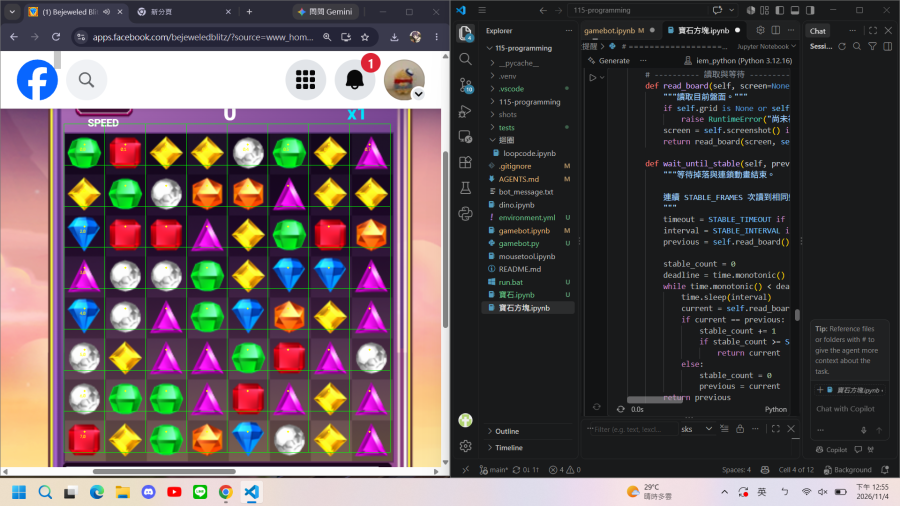

確認綠色格線是否貼合 8×8 盤面


In [362]:
# ============================================================
# 7. 第一次執行：擷取螢幕並偵測 8×8 網格
# ============================================================
# 自動偵測失敗時：
#   1. 先看下面顯示的像素座標參考圖。
#   2. 回到第 1 格設定 MANUAL_BOX=(left, top, width, height)。
#   3. 從第 1 格重新執行（或只重跑第 1、7 格）。

bot = Match3Bot()
SCREEN = bot.screenshot()
print(f"螢幕解析度：{SCREEN.shape[1]} x {SCREEN.shape[0]}")

try:
    GRID = bot.locate(screen=SCREEN, show=False)
    print("偵測到的網格：")
    print(f"  左上角：({GRID.left:.1f}, {GRID.top:.1f})")
    print(f"  單格大小：{GRID.cell_w:.2f} x {GRID.cell_h:.2f} 像素")
    print(f"  盤面大小：{GRID.width:.1f} x {GRID.height:.1f} 像素")
    show_image(annotate_grid(SCREEN, GRID), "確認綠色格線是否貼合 8×8 盤面")
except RuntimeError as exc:
    print(exc)
    print("\n以下是加上像素座標的截圖，可用來設定 MANUAL_BOX：")
    show_image(annotate_coordinates(SCREEN), "像素座標參考圖")

已學到 6 種寶石：A=橙  B=綠  C=藍  D=紫  E=紅  F=白/灰
      0  1  2  3  4  5  6  7
 0 |  B  E  A  A  F  B  A  D
 1 |  A  B  F  A  A  D  A  A
 2 |  C  E  E  D  A  B  E  A
 3 |  D  F  F  B  A  C  C  D
 4 |  C  F  D  B  C  A  A  D
 5 |  F  A  D  D  B  E  D  F
 6 |  F  B  B  D  E  D  A  D
 7 |  E  A  B  A  C  F  A  D

顏色對照：A=橙  B=綠  C=藍  D=紫  E=紅  F=白/灰


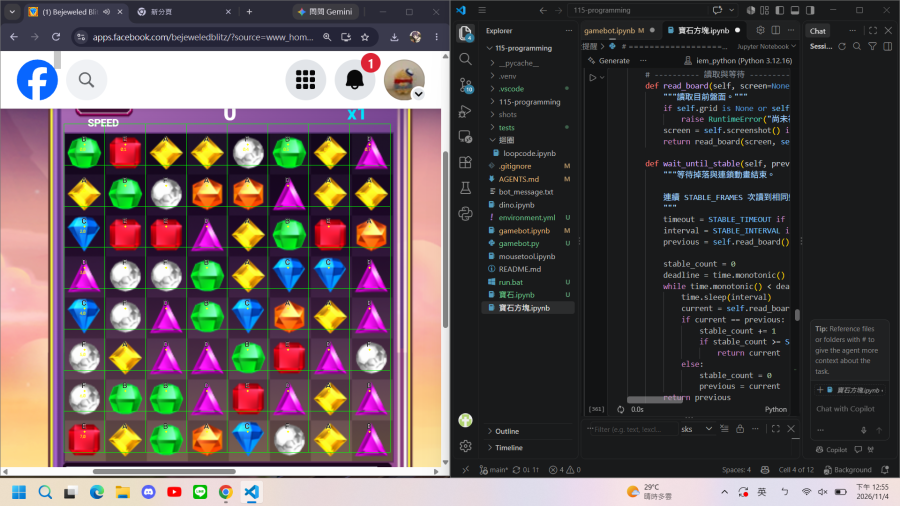

每格白字是判讀到的寶石代號


In [363]:
# ============================================================
# 8. 第二次執行：學習寶石顏色並印出盤面
# ============================================================
# 請在盤面靜止（沒有掉落、沒有連鎖動畫）時執行。
# 如果判讀結果和畫面差很多，通常是格線偏移；先回第 7 格確認。

if "bot" not in globals() or bot.grid is None:
    print("請先成功執行第 7 格。")
else:
    try:
        SCREEN = bot.screenshot()
        BOARD = bot.calibrate(screen=SCREEN, show=False)
        print(format_board(BOARD, bot.palette))
        print()
        print("顏色對照：" + palette_legend(bot.palette))
        unknown = sum(1 for row in BOARD for value in row if value < 0)
        if unknown:
            print(f"注意：有 {unknown} 格無法辨識（顯示為 .），可能正在播放動畫。")
        show_image(annotate_board(SCREEN, bot.grid, BOARD, bot.palette),
                   "每格白字是判讀到的寶石代號")
    except RuntimeError as exc:
        print(exc)

In [364]:
# ============================================================
# 9. 唯讀分析：列出最佳交換（不會移動滑鼠）
# ============================================================
# 確認這裡印出的座標、分數與盤面都合理後，再進入第 10 格。

if "bot" not in globals() or bot.palette is None:
    print("請先執行第 7、8 格完成初始化。")
else:
    bot.play(max_moves=30, dry_run=True)

唯讀模式：只分析，不會移動滑鼠
安全機制：把滑鼠移到螢幕左上角，或按 Ctrl+C 可中止。

第 1 步：找到 86 種可消除交換
  1. (5,6) <-> (5,7)  總分 1472 = 基礎 1100 + 底部加權 372  消除 8 顆  [3連(縱)+100、5連(縱)+1000]  ← 選擇
  2. (4,4) <-> (4,5)  總分 620 = 基礎 500 + 底部加權 120  消除 4 顆  [4連(縱)+500]
  3. (0,3) <-> (0,4)  總分 572 = 基礎 500 + 底部加權 72  消除 4 顆  [4連(縱)+500]
  4. (4,6) <-> (5,6)  總分 488 = 基礎 200 + 底部加權 288  消除 6 顆  [3連(縱)+100、3連(縱)+100]
  5. (4,7) <-> (5,7)  總分 488 = 基礎 200 + 底部加權 288  消除 6 顆  [3連(縱)+100、3連(縱)+100]
  特殊：5 連以上：可形成強力／炫彩特殊寶石
唯讀模式：以上是建議，不會移動滑鼠。

結束：共完成 0 步。


In [365]:
# ============================================================
# 10. 實際遊玩（預設安全模式，不會動滑鼠）
# ============================================================
# 確認第 7～9 格都正確後，才把 AUTO_PLAY 改成 True。
AUTO_PLAY = True
MAX_MOVES = 30
SWAP_MODE_NOW = "drag"  # 遊戲只接受點擊時改成 "click"

if AUTO_PLAY:
    if "bot" not in globals():
        bot = Match3Bot()
    if bot.palette is None:
        bot.setup(show=False)
    bot.play(max_moves=MAX_MOVES, dry_run=False, mode=SWAP_MODE_NOW)
else:
    print("安全模式：AUTO_PLAY=False，不會移動滑鼠。")
    print("先確認第 7～9 格的格線與盤面判讀正確，再把 AUTO_PLAY 改成 True。")



# 只走一步、確認遊戲是否接受這種交換方式：
# bot.play(max_moves=1, dry_run=False, mode=SWAP_MODE_NOW)

# 每一步都顯示盤面（比較慢）：
# bot.play(max_moves=10, dry_run=False, mode=SWAP_MODE_NOW, show_each=True)

開始自動遊玩
安全機制：把滑鼠移到螢幕左上角，或按 Ctrl+C 可中止。

第 1 步：找到 86 種可消除交換
  1. (5,6) <-> (5,7)  總分 1472 = 基礎 1100 + 底部加權 372  消除 8 顆  [3連(縱)+100、5連(縱)+1000]  ← 選擇
  2. (4,4) <-> (4,5)  總分 620 = 基礎 500 + 底部加權 120  消除 4 顆  [4連(縱)+500]
  3. (0,3) <-> (0,4)  總分 572 = 基礎 500 + 底部加權 72  消除 4 顆  [4連(縱)+500]
  4. (4,6) <-> (5,6)  總分 488 = 基礎 200 + 底部加權 288  消除 6 顆  [3連(縱)+100、3連(縱)+100]
  5. (4,7) <-> (5,7)  總分 488 = 基礎 200 + 底部加權 288  消除 6 顆  [3連(縱)+100、3連(縱)+100]
  特殊：5 連以上：可形成強力／炫彩特殊寶石
  滑鼠：(701,746) 按住拖曳到 (788,746)
  已完成並等待盤面穩定（累計 1 步）。

第 2 步：找到 84 種可消除交換
  1. (5,6) <-> (5,7)  總分 936 = 基礎 600 + 底部加權 336  消除 7 顆  [3連(縱)+100、4連(縱)+500]  ← 選擇
  2. (4,4) <-> (4,5)  總分 620 = 基礎 500 + 底部加權 120  消除 4 顆  [4連(縱)+500]
  3. (0,3) <-> (0,4)  總分 572 = 基礎 500 + 底部加權 72  消除 4 顆  [4連(縱)+500]
  4. (4,6) <-> (5,6)  總分 488 = 基礎 200 + 底部加權 288  消除 6 顆  [3連(縱)+100、3連(縱)+100]
  5. (3,4) <-> (4,4)  總分 452 = 基礎 200 + 底部加權 252  消除 6 顆  [3連(橫)+100、3連(橫)+100]
  特殊：4 連：可形成炸彈／特殊寶石
  滑鼠：(701,746) 按住拖曳到 (788,746)
  已完成並等待盤面穩定（累計 2 步）。

## 常見問題

### 1. 綠色格線沒有貼合盤面
* 可能是網頁有其他彩色區塊干擾。回到第 1 格設定：
  ```python
  MANUAL_BOX = (left, top, width, height)
  ```
  第 7 格失敗時顯示的座標圖可以直接讀出這四個值。
* 盤面必須是正方形且完整可見；若網頁有捲動或縮放，請先調整好再重新執行第 7 格。
* 若 Windows 顯示縮放不是 100%，截圖像素與滑鼠座標可能有比例差；請把顯示縮放設為 100%，或改用 `MANUAL_BOX` 微調。
* 設定 `MANUAL_BOX` 後，底下所有格線、取樣與滑鼠座標都會跟著更新。

### 2. 盤面代號與畫面顏色不一致
* 請在盤面靜止時重跑第 8 格。
* 若某兩色被判定成同一種，調低 `PALETTE_MERGE_DIST`（例如 22 → 15）。
* 若同一種寶石被拆成兩類，調高 `PALETTE_MERGE_DIST`（例如 22 → 30）。
* 遊戲寶石種類不是 6 種時，修改第 1 格的 `GEM_TYPES`。

### 3. 有交換動作，但盤面沒有改變
* 遊戲可能只接受拖曳：把 `SWAP_MODE` 或第 10 格的 `SWAP_MODE_NOW` 改成 `"drag"`。
* 只接受點擊：改成 `"click"`。
* 格線仍有些微偏移：用 `MANUAL_BOX` 微調，或在第 7 格確認每個黃點都落在寶石中央。
* 動畫太慢：把第 1 格的 `SETTLE_TIME`、`STABLE_TIMEOUT` 調大。

### 4. 防卡死一直隨機交換
* 若遊戲有「重整」按鈕，設定：
  ```python
  STUCK_ACTION = "shuffle"
  SHUFFLE_POINT = (x, y)  # 重整按鈕的螢幕座標
  ```
* 否則維持 `STUCK_ACTION = "random"`，程式會在盤面內隨機交換。
* 連續 `MAX_STUCK_ROUNDS` 輪都失敗會自動停止，避免無限亂點。

### 5. 如何緊急停止
* 把滑鼠快速移到**螢幕左上角**，PyAutoGUI 會拋出 `FailSafeException`。
* 或按 Jupyter 的 **Interrupt Kernel**（Ctrl+C）。
* 若擔心亂點，先按 Ctrl+C，再把遊戲視窗切到背景。

### 6. 想調整策略
* `BOTTOM_ROW_BONUS`：底部加權強度；越大越偏好消除下方。
* `MATCH_SCORES`：3/4/5 連的分數。
* `GEM_TYPES`、`PALETTE_MERGE_DIST`、`PALETTE_MAX_DIST`：顏色辨識靈敏度。
* `MAX_MOVES`、`SWAP_MODE_NOW`：遊玩步數與交換方式。

> 本程式只適合個人練習與自動化實驗；請遵守遊戲網站的服務條款。